# Experiment 5: Fuzzy Linguistic Variables (Low, Medium, High)

**Aim:** To create fuzzy linguistic variables such as Low, Medium, and High using membership functions in Python.

## Theory
A **linguistic variable** takes words as values (e.g. Temperature = *Low, Medium, High*).
Each word (term) is a fuzzy set defined by a membership function over a universe of discourse.
**Fuzzification** converts a crisp input into membership degrees of each linguistic term.

### Step 1: Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
%matplotlib inline

### Step 2: Define the linguistic variable 'Temperature' (0-50 °C)

In [2]:
temp = np.arange(0, 51, 0.5)
low    = fuzz.trapmf(temp, [0, 0, 10, 25])
medium = fuzz.trimf(temp,  [10, 25, 40])
high   = fuzz.trapmf(temp, [25, 40, 50, 50])

### Step 3: Plot the linguistic terms

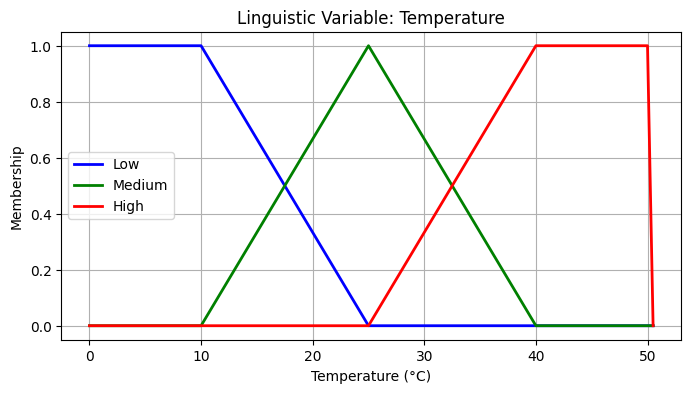

In [3]:
plt.figure(figsize=(8, 4))
plt.plot(temp, low,    'b', lw=2, label='Low')
plt.plot(temp, medium, 'g', lw=2, label='Medium')
plt.plot(temp, high,   'r', lw=2, label='High')
plt.title('Linguistic Variable: Temperature')
plt.xlabel('Temperature (°C)'); plt.ylabel('Membership'); plt.legend(); plt.grid(True); plt.show()

### Step 4: Fuzzification of crisp inputs

In [4]:
def fuzzify(value):
    return {
        'Low'   : float(fuzz.interp_membership(temp, low,    value)),
        'Medium': float(fuzz.interp_membership(temp, medium, value)),
        'High'  : float(fuzz.interp_membership(temp, high,   value)),
    }

for t in [5, 15, 25, 32, 45]:
    m = fuzzify(t)
    best = max(m, key=m.get)
    print(f"T = {t:>2} °C -> {({k: round(v,2) for k,v in m.items()})}  => mostly '{best}'")

T =  5 °C -> {'Low': 1.0, 'Medium': 0.0, 'High': 0.0}  => mostly 'Low'
T = 15 °C -> {'Low': 0.67, 'Medium': 0.33, 'High': 0.0}  => mostly 'Low'
T = 25 °C -> {'Low': 0.0, 'Medium': 1.0, 'High': 0.0}  => mostly 'Medium'
T = 32 °C -> {'Low': 0.0, 'Medium': 0.53, 'High': 0.47}  => mostly 'Medium'
T = 45 °C -> {'Low': 0.0, 'Medium': 0.0, 'High': 1.0}  => mostly 'High'


### Step 5: Visualise fuzzification of T = 32 °C

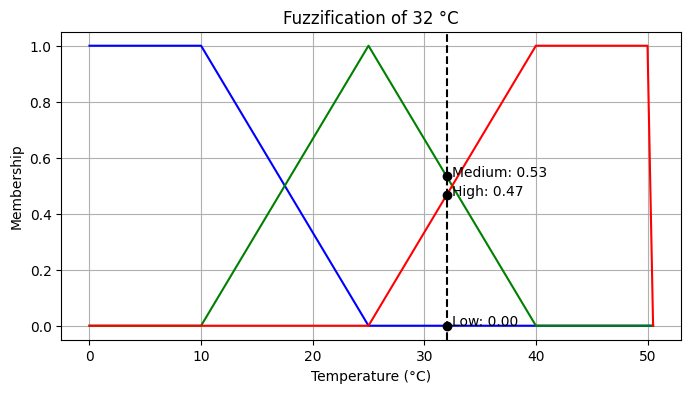

In [5]:
t0 = 32
m = fuzzify(t0)
plt.figure(figsize=(8, 4))
plt.plot(temp, low, 'b', temp, medium, 'g', temp, high, 'r')
plt.axvline(t0, color='k', ls='--')
for name, mu in m.items():
    plt.plot(t0, mu, 'ko')
    plt.text(t0 + 0.5, mu, f"{name}: {mu:.2f}")
plt.title(f'Fuzzification of {t0} °C'); plt.xlabel('Temperature (°C)'); plt.ylabel('Membership'); plt.grid(True); plt.show()

### Step 6: Another linguistic variable - Speed (using Gaussian MFs)

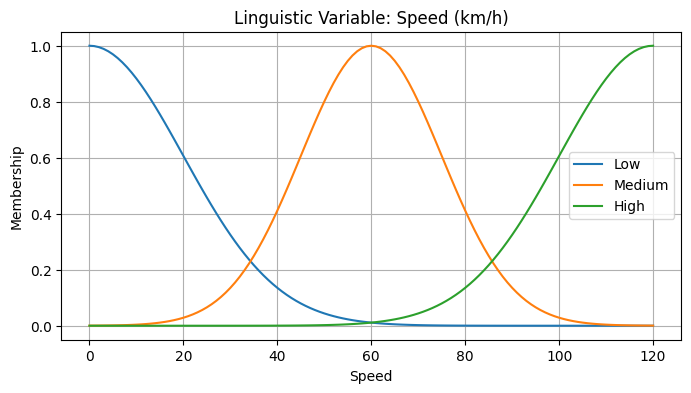

In [6]:
speed = np.arange(0, 121, 1)
s_low  = fuzz.gaussmf(speed, 0, 20)
s_med  = fuzz.gaussmf(speed, 60, 15)
s_high = fuzz.gaussmf(speed, 120, 20)
plt.figure(figsize=(8, 4))
plt.plot(speed, s_low, label='Low'); plt.plot(speed, s_med, label='Medium'); plt.plot(speed, s_high, label='High')
plt.title('Linguistic Variable: Speed (km/h)'); plt.xlabel('Speed'); plt.ylabel('Membership'); plt.legend(); plt.grid(True); plt.show()

## Conclusion
Linguistic variables with the terms Low, Medium and High were defined using trapezoidal, triangular and Gaussian membership functions, and crisp values were fuzzified into degrees of membership.